# 11주차: 부분 GPU 보관과 선택적 CPU 보관

## 개요: 무엇을 왜 비교하는가?

이 프로젝트는 LLM이 도구 실행을 기다리는 동안 사용하지 않는 **KV cache를 GPU에 남길지, CPU로 옮길지, 삭제한 뒤 복귀 시 재계산할지**를 비교한다. KV cache는 이전 토큰의 attention 계산 결과이며, 보관하면 후속 턴의 중복 계산을 줄이지만 메모리나 전송 비용을 사용한다.

이번 실험은 9주차의 예약·prefill 대기 원인 분석과 10주차의 Watermark 입장 상한 실험에서 나아가, **어떤 KV를 얼마나 남길지**와 **회수한 KV를 CPU에 보관할 가치가 있는지**를 나누어 확인한다. GPU 점유율 상한에 맞췄다는 사실보다 실제 응답 지연과 복귀 지연, 전송·재계산 비용을 함께 평가하는 것이 목적이다.

### 핵심 비교 정책

아래 네 정책은 모두 같은 새 block 엔진을 사용한다. 기존에도 메모리는 16-token block 단위로 할당했지만, 기존 엔진의 회수 단위는 세션 전체였다. 새 엔진은 필요한 block만 회수하고 나머지는 GPU에 남길 수 있다. 여기서 prefix는 세션의 앞부분 KV, suffix는 뒷부분 KV를 뜻한다.

| 정책 / 코드명 | GPU 공간이 부족할 때 | CPU 사용과 복귀 시 처리 | 이 비교로 확인할 것 |
|---|---|---|---|
| **Block LRU evict** / `prefix_lru_evict` | 오래 idle인 세션부터 뒷부분 block을 필요한 만큼 삭제 | CPU를 쓰지 않고, 복귀 시 없는 토큰만 재계산 | T-LRU와 같은 부분 회수·재계산 모델의 기준선 |
| **T-LRU** / `tlru` | 예상 재계산이 prefill 예산 안에 드는 suffix를 우선 회수하고, 부족하면 block LRU로 회수 | CPU를 쓰지 않고, 남긴 prefix 뒤의 누락 토큰을 재계산 | 같은 block LRU보다 보관량 배분을 바꾸면 tail 지연이 줄어드는가? |
| **Block LRU offload** / `prefix_lru_offload` | 같은 block LRU 순서로 GPU block을 회수 | CPU 보관을 항상 시도하고, CPU가 차면 회수 가능한 CPU LRU block을 교체. 복귀 시 reload, 삭제된 부분은 재계산 | HotPrefix와 같은 GPU 회수 순서를 사용하는 CPU 보관 기준선 |
| **HotPrefix admission** / `hotprefix_admission` | 기본 GPU 회수 순서는 block LRU로 유지 | 접근 빈도·최근성에 따라 CPU에 선택적으로 보관·교체하고, 거절한 block은 삭제. 복귀 시 reload 또는 재계산 | 선택적 CPU 보관이 전송량 절약을 실제 지연 개선으로 연결하는가? |

T-LRU의 기본값은 **prefill 예산 200ms, 다음 prompt 추정 160 tokens**다. 200ms는 자기 prefill의 계산 예산이며 입장·대기열·전송까지 포함한 전체 TTFT 보장이 아니다. HotPrefix의 기본값은 **접근 빈도 기준 F=2**, 사용 시 clock을 15로 초기화하고 100회 prefill 완료마다 1씩 감소시키는 설정이다. clock은 최근성을 나타내는 카운터다. 기준을 통과하지 못해 CPU 보관을 거절하는 것은 **요청 입장 거절과 다른 동작**이다.

### 기존 정책은 어떤 역할로 포함하는가?

주 평가에는 아래 기존 7개 정책도 포함해 총 11개 정책/기준선을 실행했다. 앞의 네 정책에 대한 판단은 **T-LRU ↔ Block LRU evict**, **HotPrefix admission ↔ Block LRU offload**의 짝비교를 우선한다.

| 기존 정책 / 코드명 | 동작 요약 |
|---|---|
| Pin-All / `pin_all` | 도구 대기 중에도 KV를 GPU에 유지한다. 회수하지 못해 공간이 없으면 새 턴은 입장을 기다린다. |
| Evict/Recompute / `evict_recompute` | 도구 대기에 들어가면 KV를 삭제하고 복귀 시 재계산한다. |
| Fixed TTL / `fixed_ttl` | 정해진 TTL 동안 GPU에 유지한 뒤 삭제한다. |
| LRU offload / `lru_offload` | GPU 공간이 부족하면 오래 idle인 세션의 KV 전체를 CPU로 옮긴다. CPU 공간이 없으면 삭제한다. |
| Duration-Aware / `duration_aware` | 여유 공간과 도구 대기·전송 비용에 따라 KEEP/OFFLOAD/EVICT를 고른다. 현재는 trace의 실제 대기시간을 쓰는 oracle 참조 정책이다. |
| Watermark offload / `watermark_offload` | 기본 90%의 GPU 입장 상한 안에서 들어오도록 LRU offload로 공간을 확보한다. |
| Capped Pin-All / `pin_all_capped` | 같은 기본 90% 상한을 적용하되 KV를 회수하지 않는 대조군이다. |

기존 `lru_offload`는 표에서 참고값으로 제시한다. 기존 엔진과 새 block 엔진 사이에는 회수 단위뿐 아니라 진행 중 전송의 공간 계산·CPU 교체 방식도 달라서, 두 엔진 사이의 차이를 새 정책 하나의 효과로 해석하지 않는다. 환경별 그래프는 위 핵심 네 정책을 보여준다.

### 실험 질문과 읽는 순서

1. **부분 GPU 보관:** T-LRU가 같은 GPU-only block LRU보다 재계산과 실제 복귀 지연을 줄이는가?
2. **선택적 CPU 보관:** HotPrefix가 전송을 줄일 때, 추가 재계산·대기 비용까지 고려해도 유리한가?
3. **환경 의존성:** PCIe가 느리거나 CPU 풀이 작아지면 정책 간 유불리가 바뀌는가?
4. **병목 확인:** 자기 prefill 감소가 prefill 대기열에 가려지는가? 기준값이나 GPU 회수 순서를 바꿔도 결과가 유지되는가?

여기서는 초기 7,290회의 **일반 요청 P95 TTFT**(요청 도착→첫 토큰), **복귀 P95**(실제 도구 종료→다음 첫 토큰), 전송량(GiB/run), 재계산량(tokens/run), 완료율·거절률을 읽는다. 지연과 비용은 서로 교환될 수 있으므로 함께 비교한다. 기존 Peak 90%·상대 SLO는 서비스 우수성의 단독 근거로 삼지 않는다. 비제약 참조와 추가 조건에서의 재평가는 별도 평가 노트북에서 다룬다.

아래는 **비교 조건 → 주 평가·짝비교 → 설정별 환경 그래프 3개와 평균 → 환경 민감도 → 기준값·GPU 순서 ablation → 복귀 지연 분해 → 실험 결과·인사이트** 순서다.

T-LRU Algorithm 1과 HotPrefix §3.2–3.3의 정책을 세션별 block chain 시뮬레이터에서 평가한다. **HotPrefix 전체 시스템 재현, 선제 승격, CUDA pipeline, 실제 GPU 측정은 아니다.** 세션 간 prefix 공유는 입력에 없으므로 만들지 않는다.

[통합 보고서](../docs/week11_experiment.md) · [평가 재검토 노트북](week11_evaluation_review.ipynb)

[T-LRU 논문](https://arxiv.org/html/2510.15152v1#S4) · [HotPrefix 논문](https://doi.org/10.1145/3749168)

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "docs/data/week11/summary.csv").exists())
DATA = ROOT / "docs/data/week11"
raw = pd.read_csv(DATA / "summary.csv")
comparison = pd.read_csv(DATA / "comparison.csv")
pairs = pd.read_csv(DATA / "paired.csv")
hardware_pairs = pd.read_csv(DATA / "paired_hardware.csv")
manifest = json.loads((DATA / "experiment.json").read_text(encoding="utf-8"))
checks = json.loads((DATA / "validation.json").read_text(encoding="utf-8"))
assert len(raw) == manifest["expected_runs"] == manifest["completed_runs"]
assert raw.groupby(["setting", "condition", "seed"]).trace_sha256.nunique().max() == 1
display(raw.groupby("suite").size().rename("runs").to_frame())
print(checks)

{'runs': 7290, 'suites': {'ablation': 810, 'hardware': 2025, 'main': 4455}, 'unique_input_traces': 405, 'all_paired_inputs_identical': True, 'all_source_hashes_match': True, 'selective_off_exact_matches': 135, 'cpu_free_hardware_exact_matches': 810}


,runs
suite,
ablation,810
hardware,2025
main,4455


## 비교 조건

주 실험은 기존 3개 설정 × 9개 조건 × seed 0–14 × 11개 정책/기준선이다. hardware와 threshold ablation은 seed 0–4를 쓴다. 환경 간 그림은 기본 환경도 같은 seed 0–4로 제한한다.

새 정책의 입장 상한은 모두 100%. CPU를 쓰지 않는 T-LRU의 기준선은 `prefix_lru_evict`, 선택적 CPU 보관의 기준선은 `prefix_lru_offload`다. 기존 `lru_offload`와 새 block 기준선의 차이에는 **회수 단위·CPU 교체·in-flight 처리 차이**가 있으므로 정책 우수성의 근거로 합치지 않는다.

각 run의 P95를 구한 뒤 seed·조건별로 평균낸 값이다. 전체 요청을 합친 P95가 아니다.

In [2]:
variants = ["lru_offload", "prefix_lru_evict", "tlru", "prefix_lru_offload", "hotprefix_admission"]
main = raw[(raw.suite == "main") & raw.variant.isin(variants)].copy()
main["transfer_gib"] = main.transfer_bytes / 2**30
metrics = ["normal_p95_ttft_ms", "resume_p95_ms", "transfer_gib", "recomputed_tokens", "stress_completion_pct"]
display(main.groupby(["setting", "variant"])[metrics].mean().round(3))

normal_p95_ttft_ms  ...  stress_completion_pct
setting variant                                  ...                       
180s_02 hotprefix_admission             292.495  ...                  100.0
        lru_offload                     270.057  ...                  100.0
        prefix_lru_evict                385.223  ...                  100.0
        prefix_lru_offload              270.450  ...                  100.0
        tlru                            342.587  ...                  100.0
180s_03 hotprefix_admission             497.208  ...                  100.0
        lru_offload                     447.518  ...                  100.0
        prefix_lru_evict                759.476  ...                  100.0
        prefix_lru_offload              448.522  ...                  100.0
        tlru                            715.200  ...                  100.0
60s_02  hotprefix_admission             314.126  ...                  100.0
        lru_offload                     308.061  ...                  100.0
        prefix_lru_evict                329.457  ...                  100.0
        prefix_lru_offload              307.967  ...                  100.0
        tlru                            314.755  ...                  100.0

[15 rows x 5 columns]

## T-LRU와 HotPrefix의 paired 효과

아래 차이는 **후보 − 기준선**이다. 지연·전송·재계산은 음수가 감소를 뜻한다. `ALL9`는 먼저 같은 seed 안에서 9조건을 평균내고, seed를 단위로 bootstrap한 95% CI다. threshold를 고른 뒤 같은 seed로 성능을 재확인하는 튜닝은 하지 않았다.

In [3]:
primary = pairs[(pairs.suite == "main") & (pairs.condition == "ALL9") & pairs.candidate.isin(["tlru", "hotprefix_admission"])]
columns = ["setting", "candidate", "baseline", "paired_runs", "identical_requests",
           "normal_p95_ttft_ms_delta", "normal_p95_ttft_ms_ci_low", "normal_p95_ttft_ms_ci_high",
           "resume_p95_ms_delta", "resume_p95_ms_ci_low", "resume_p95_ms_ci_high",
           "transfer_bytes_delta_pct", "recomputed_tokens_delta"]
display(primary[columns].round(3))

,setting,candidate,baseline,paired_runs,identical_requests,normal_p95_ttft_ms_delta,normal_p95_ttft_ms_ci_low,normal_p95_ttft_ms_ci_high,resume_p95_ms_delta,resume_p95_ms_ci_low,resume_p95_ms_ci_high,transfer_bytes_delta_pct,recomputed_tokens_delta
360,180s_02,hotprefix_admission,prefix_lru_offload,135,15,22.045,14.724,30.198,96.083,70.672,120.311,-20.469,15028.844
362,180s_02,tlru,prefix_lru_evict,135,19,-42.637,-53.234,-32.913,-97.077,-123.172,-76.182,NaN,-5690.452
390,180s_03,hotprefix_admission,prefix_lru_offload,135,2,48.686,38.345,60.308,159.574,134.684,182.974,-23.627,46863.333
392,180s_03,tlru,prefix_lru_evict,135,3,-44.277,-56.563,-34.113,-79.028,-103.297,-53.784,NaN,-7584.867
420,60s_02,hotprefix_admission,prefix_lru_offload,135,63,6.160,0.243,15.727,44.807,18.433,75.215,-25.009,2617.104
422,60s_02,tlru,prefix_lru_evict,135,69,-14.702,-26.199,-5.728,-63.225,-99.017,-29.756,NaN,-1246.741


## 설정별 PCIe·CPU 환경 비교 그래프

**60s/stress 0.2 → 180s/stress 0.2 → 180s/stress 0.3 → 세 설정 평균** 순서로 제시한다. stress 0.2/0.3은 설정의 기본 stress 세션 도착률(초당)이며, 각 설정에는 기존 9가지 워크로드 조건이 있다.

각 그림은 핵심 네 정책의 일반 P95·복귀 P95·전송량·재계산량을 네 가지 PCIe/CPU 환경에서 비교한다. 기본 환경은 PCIe 12GB/s·CPU 64GiB, 나머지는 느린 PCIe(1.5GB/s), 작은 CPU 풀(1GiB), 둘을 함께 적용한 환경이다. **환경 비교에는 기본 환경도 seed 0–4만 사용한다**. 앞선 주 평가 표의 seed 0–14 평균과 숫자가 다를 수 있다.

세 설정 평균은 설정별 9조건×5seed 평균에 각각 **1/3 가중치**를 준 산술평균이다. 지연은 run별 P95의 평균으로, 요청을 모두 합쳐 다시 계산한 P95가 아니다. 전송·재계산은 길이가 다른 run의 누계 비용을 평균낸 것이며 시간당 비용이나 처리량으로 해석하지 않는다. 평균 그림만으로 설정별 결과를 대체하지 않는다.

### 1. 60s / stress 0.2

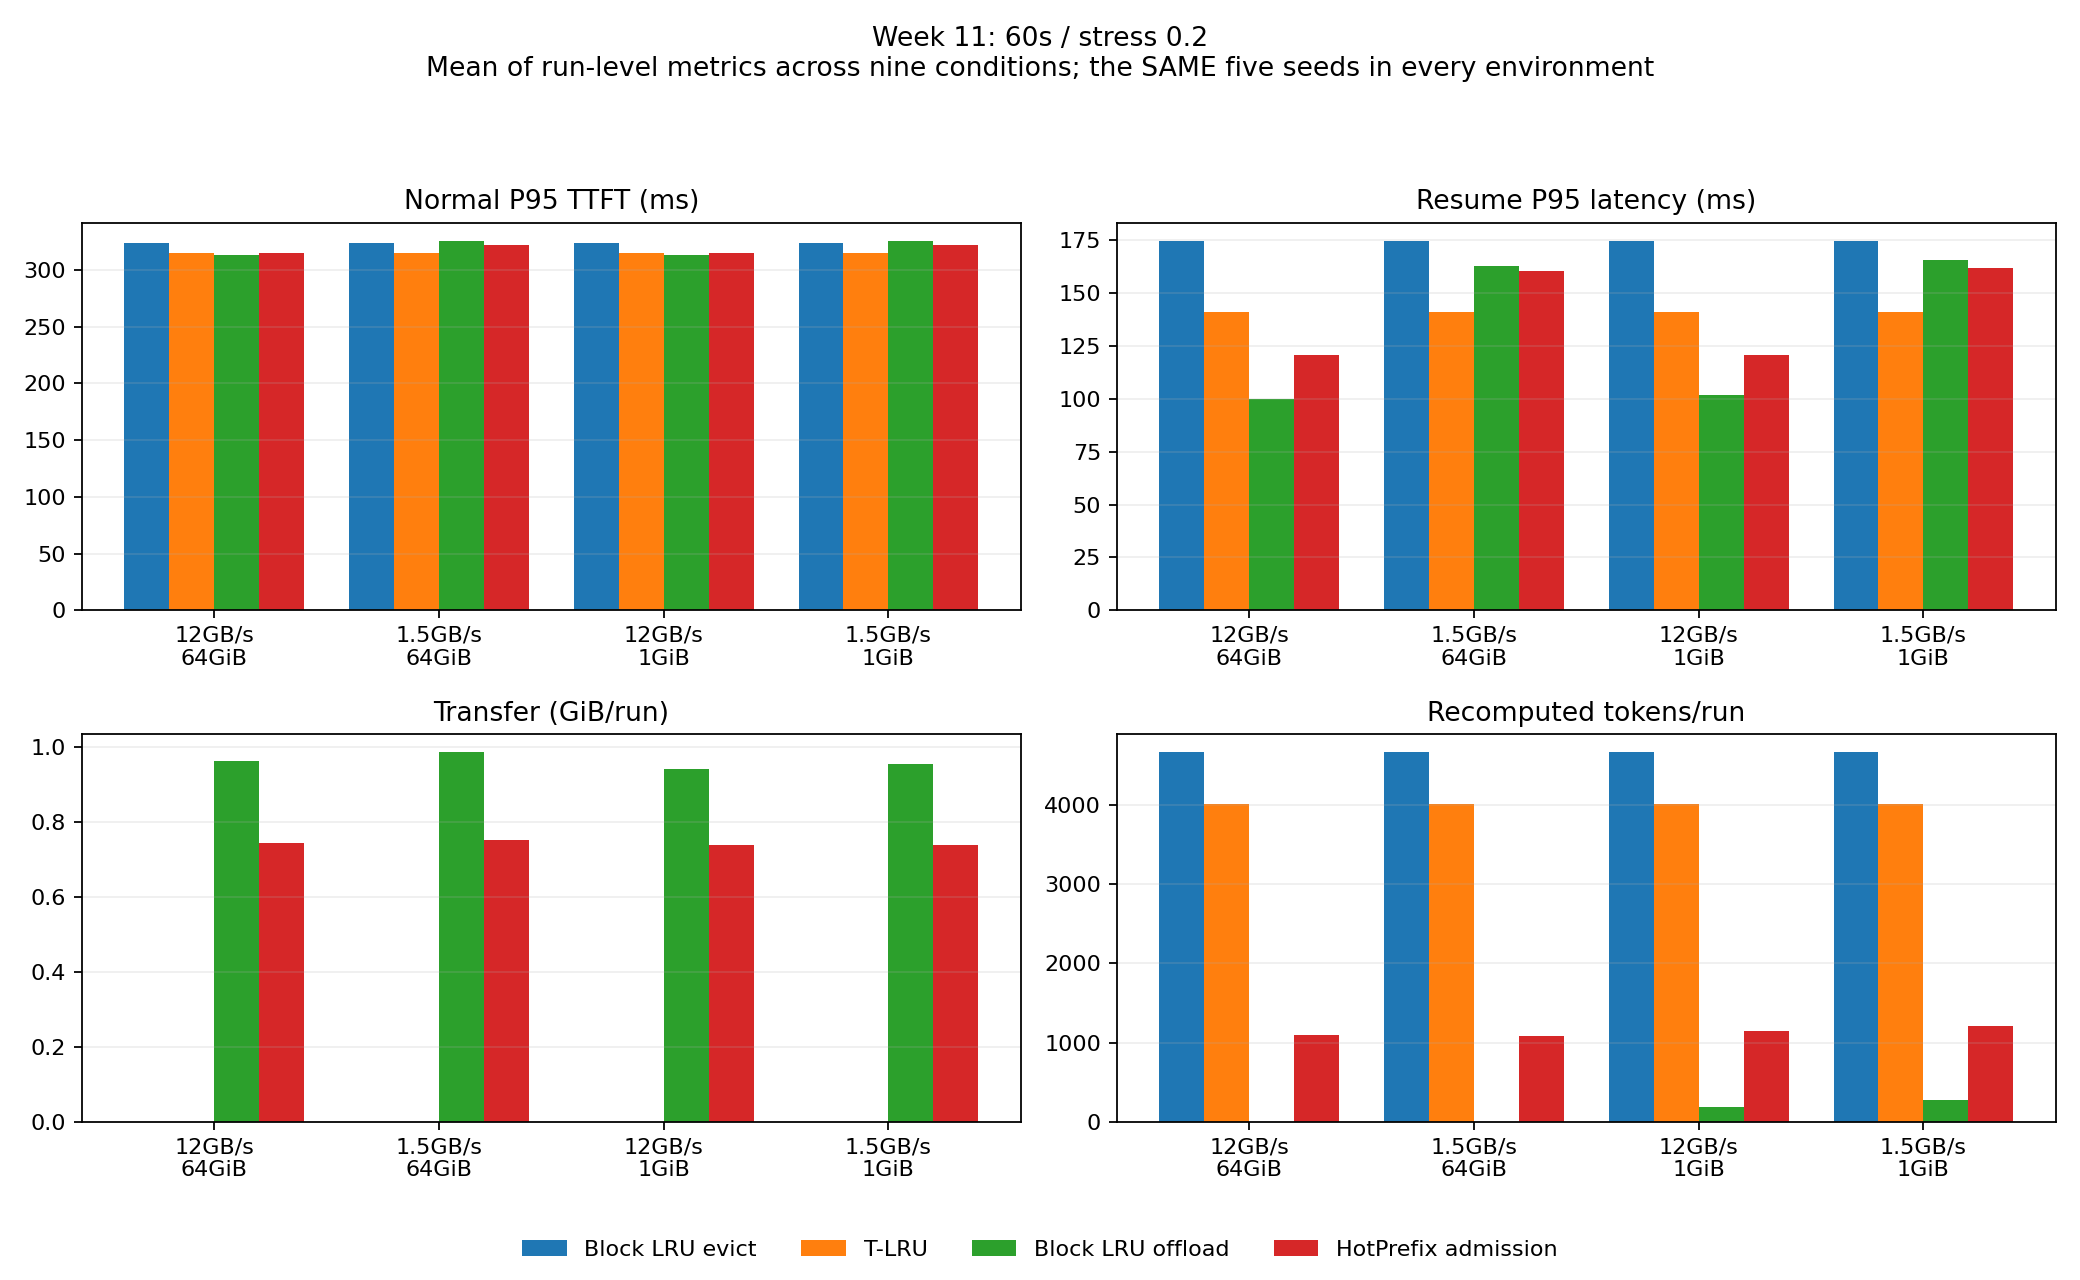

In [4]:
figure_paths = [ROOT / "docs/figures" / f"{name}.png" for name in (
    "week11_policy_comparison_60s_02", "week11_policy_comparison",
    "week11_policy_comparison_180s_03", "week11_policy_comparison_average")]
assert len(figure_paths) == 4
assert all(path.exists() for path in figure_paths)
display(Image(filename=str(figure_paths[0])))

### 2. 180s / stress 0.2

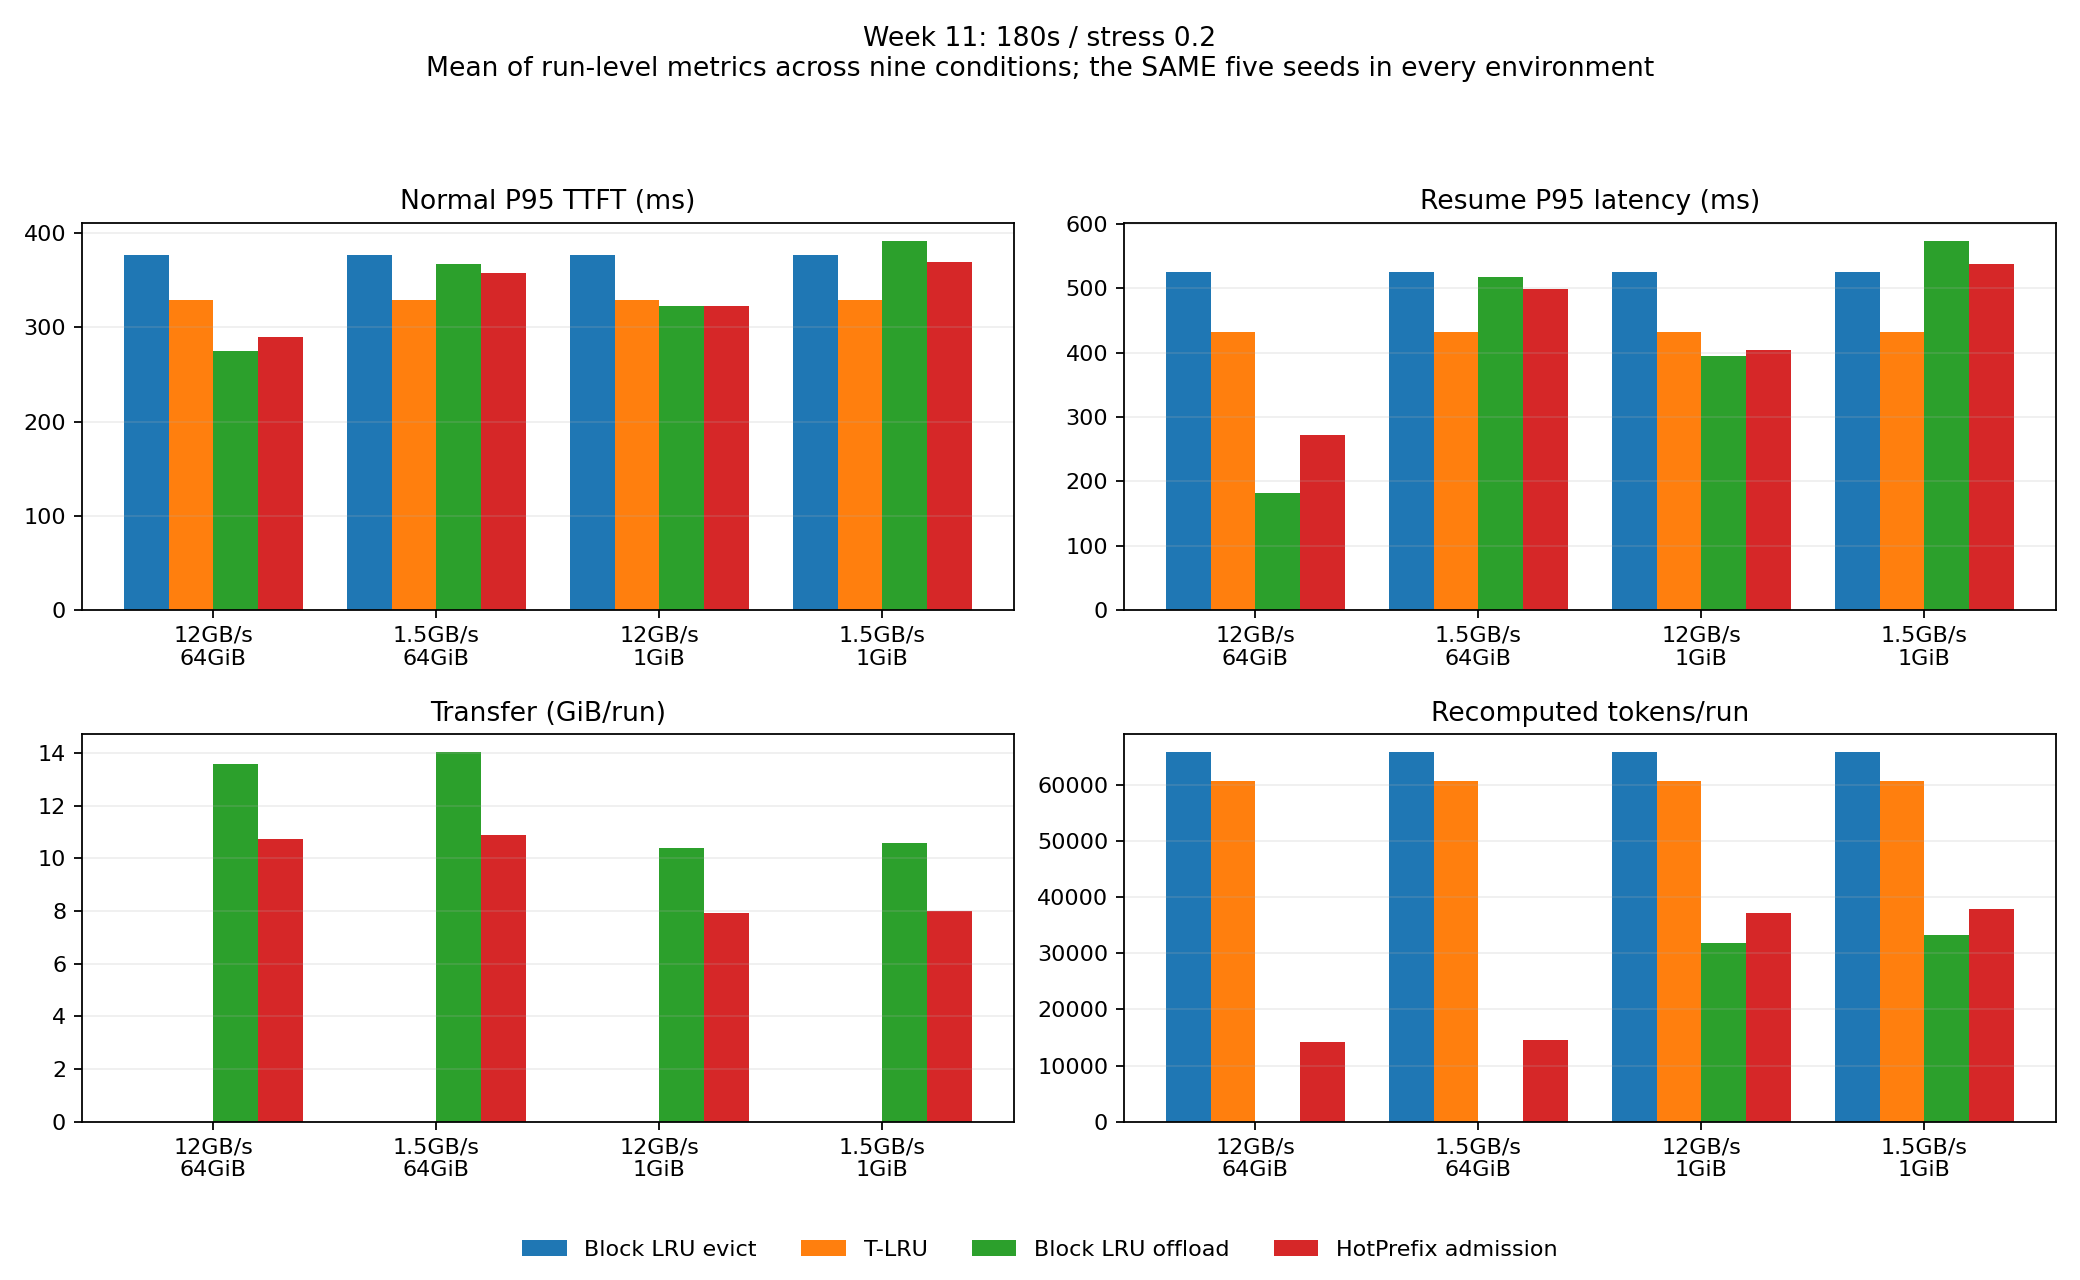

In [5]:
display(Image(filename=str(figure_paths[1])))

### 3. 180s / stress 0.3

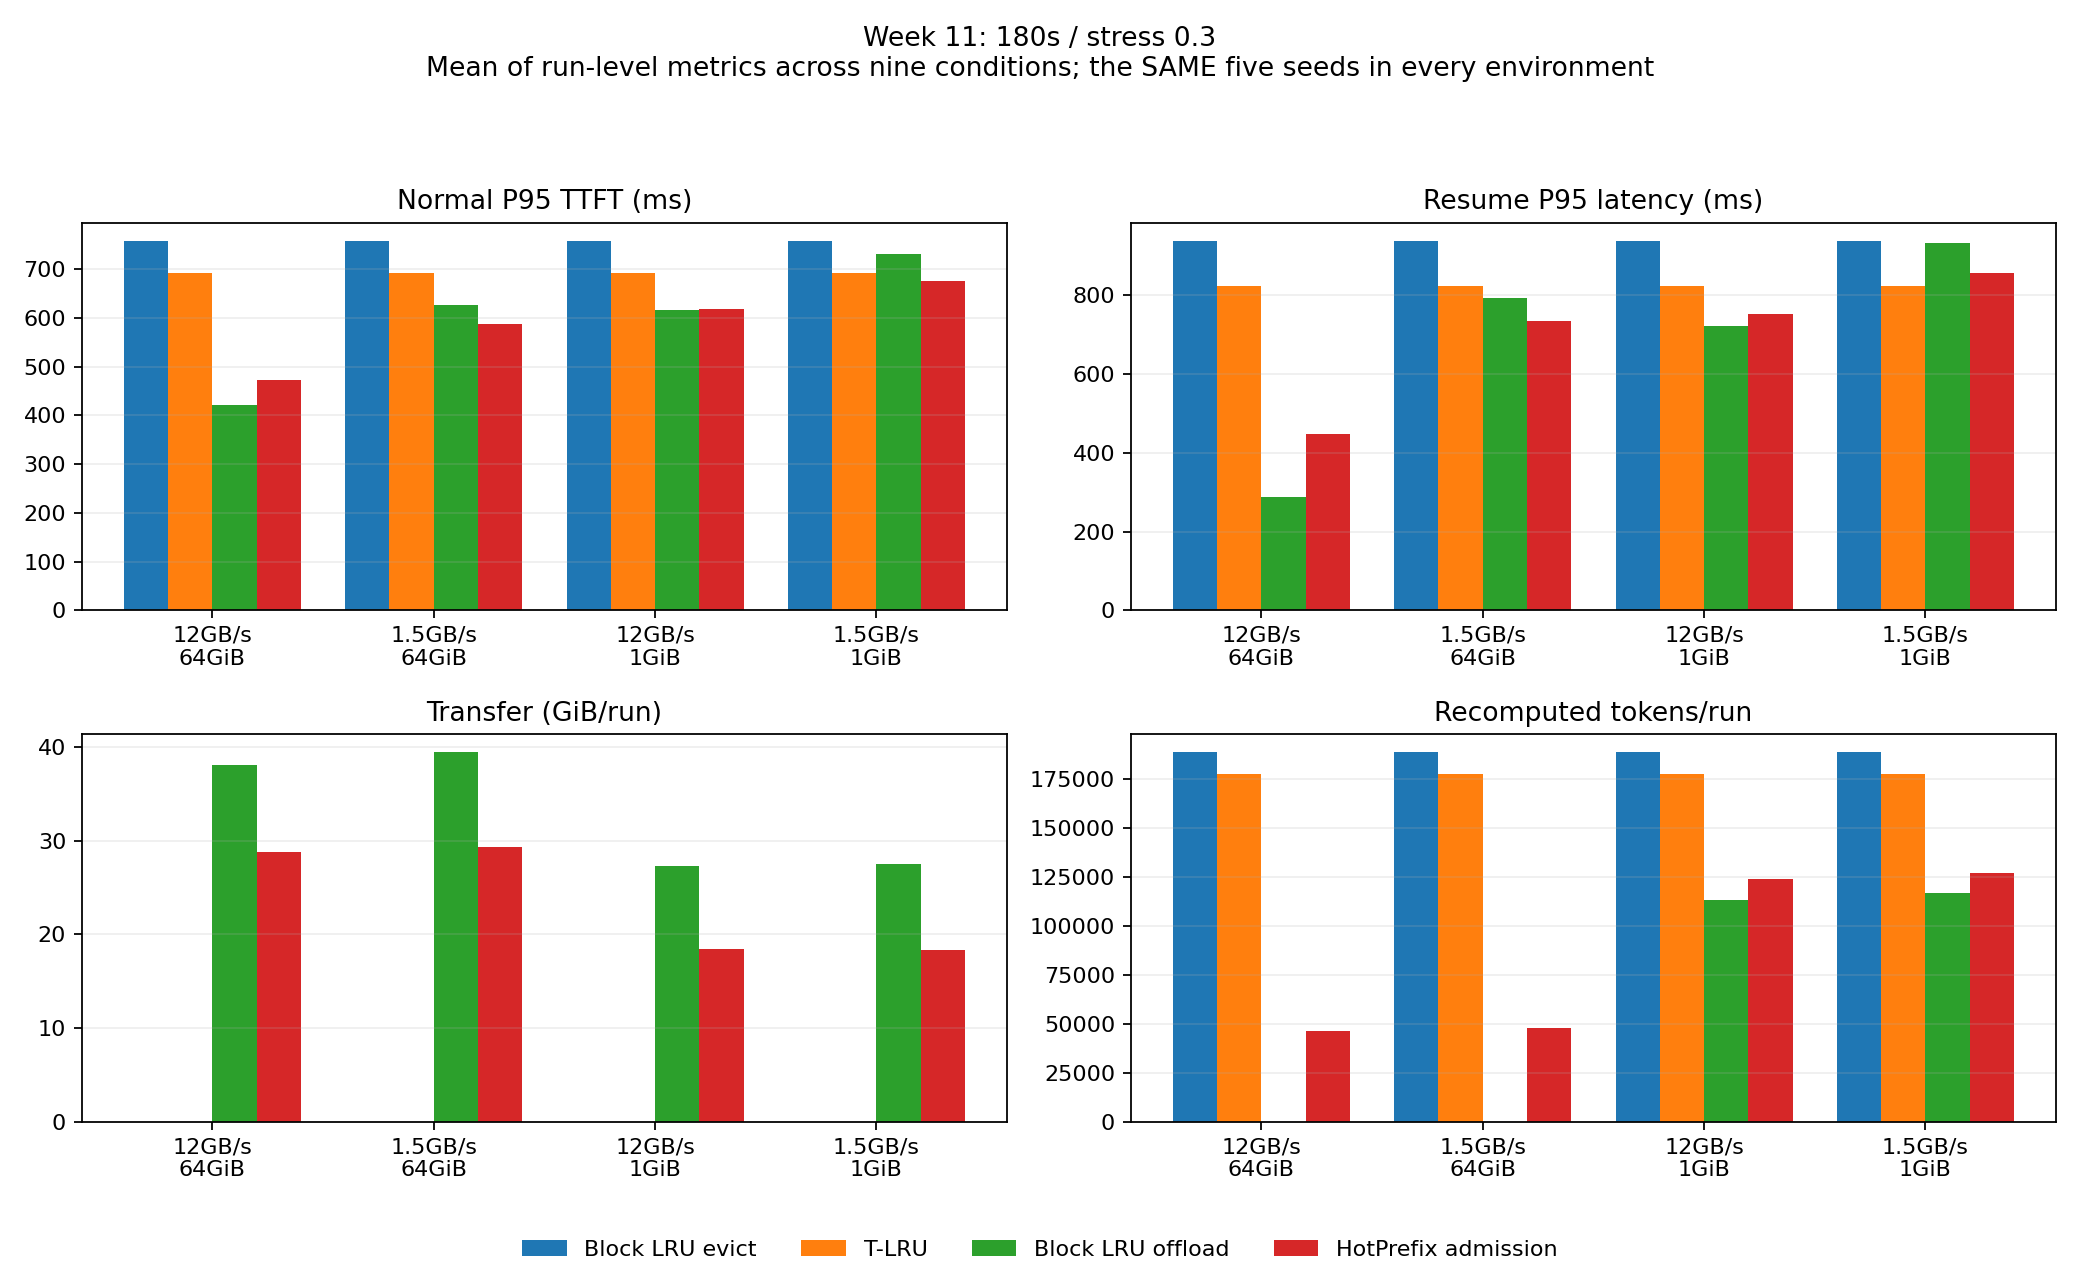

In [6]:
display(Image(filename=str(figure_paths[2])))

### 4. 세 설정 평균: 설정별 동일 가중치

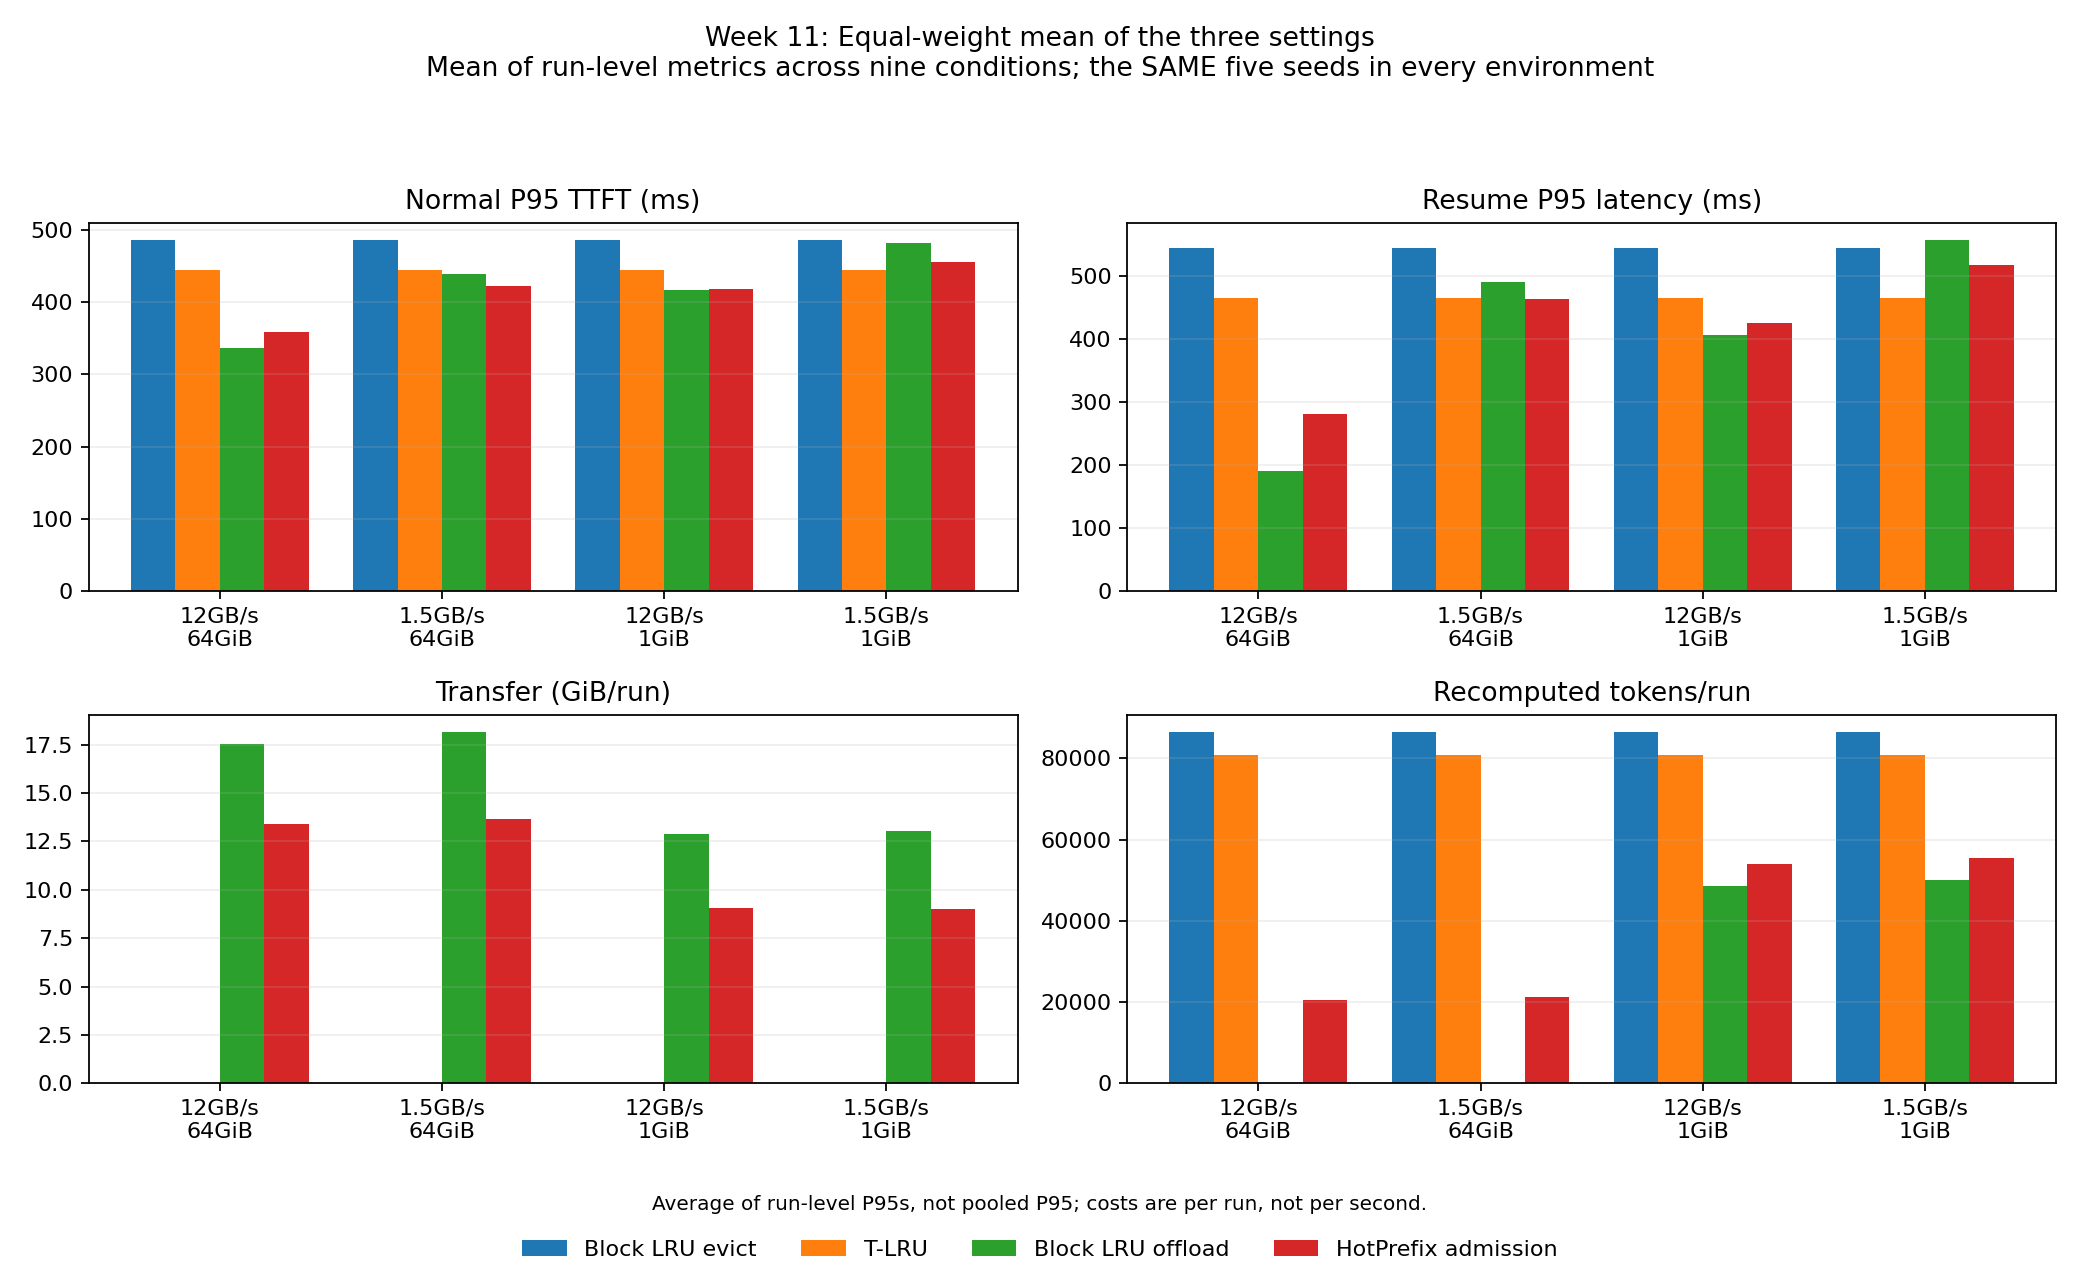

In [7]:
display(Image(filename=str(figure_paths[3])))

## PCIe·CPU 민감도: 같은 다섯 seed

전송량 감소만으로 성공이라고 판단하지 않는다. 전송 대기 감소가 재계산 증가와 prefill 대기에 의해 상쇄되는지 함께 읽는다. 아래 기본 환경도 seed 0–4만 사용한다.

In [8]:
hw = hardware_pairs[(hardware_pairs.condition == "ALL9") & (hardware_pairs.setting == "180s_02") & hardware_pairs.candidate.isin(["tlru", "hotprefix_admission"])]
display(hw[["environment", "candidate", "baseline", "normal_p95_ttft_ms_delta", "resume_p95_ms_delta",
            "transfer_bytes_delta_pct", "recomputed_tokens_delta", "stress_completion_pct_delta"]].round(3))

,environment,candidate,baseline,normal_p95_ttft_ms_delta,resume_p95_ms_delta,transfer_bytes_delta_pct,recomputed_tokens_delta,stress_completion_pct_delta
0,slow_pcie,hotprefix_admission,prefix_lru_offload,-9.154,-19.374,-22.243,14599.422,0.0
1,slow_pcie,tlru,prefix_lru_evict,-48.037,-92.190,NaN,-5053.133,0.0
20,slow_small,hotprefix_admission,prefix_lru_offload,-22.148,-36.164,-24.680,4665.756,0.0
21,slow_small,tlru,prefix_lru_evict,-48.037,-92.190,NaN,-5053.133,0.0
40,small_cpu,hotprefix_admission,prefix_lru_offload,0.178,9.183,-23.689,5327.444,0.0
41,small_cpu,tlru,prefix_lru_evict,-48.037,-92.190,NaN,-5053.133,0.0
180,default,hotprefix_admission,prefix_lru_offload,14.679,89.560,-20.954,14261.111,0.0
182,default,tlru,prefix_lru_evict,-48.037,-92.190,NaN,-5053.133,0.0


## threshold·GPU 순서 ablation

T-LRU는 100/200/400ms의 prefill 예산을 확인한다. 전체 TTFT 보장은 아니다. HotPrefix의 기본 frequency threshold는 2이고 1/3을 별도로 평가한다. `gpu_hotness`는 논문 §3.3.1의 GPU 순서를 추가한다. `selective_off`는 동일 엔진의 LRU offload와 정확히 같아야 하는 음성 대조군이다.

HotPrefix aging clock은 사용 시 15로 reset하고 100 prefill 완료마다 1 감소시킨다. 15는 논문의 예시값, 100은 논문에 요청 수가 명시되지 않아 사전에 정한 모델 설정이다.

In [9]:
abl = pairs[(pairs.suite == "ablation") & (pairs.setting == "180s_02") & (pairs.condition == "ALL9")]
display(abl[["candidate", "baseline", "paired_runs", "identical_requests", "normal_p95_ttft_ms_delta",
             "resume_p95_ms_delta", "transfer_bytes_delta_pct", "recomputed_tokens_delta"]].round(3))
off = pairs[(pairs.suite == "ablation") & (pairs.candidate == "hotprefix_selective_off") & (pairs.condition != "ALL9")]
assert (off.identical_requests == off.paired_runs).all()
print("Selective-off exact matches:", int(off.identical_requests.sum()))

Selective-off exact matches: 135


,candidate,baseline,paired_runs,identical_requests,normal_p95_ttft_ms_delta,resume_p95_ms_delta,transfer_bytes_delta_pct,recomputed_tokens_delta
0,hotprefix_f1,hotprefix_admission,45,5,-14.679,-89.560,26.501,-14257.200
1,hotprefix_f3,hotprefix_admission,45,5,58.961,188.631,-72.898,37542.244
2,hotprefix_gpu_hotness,hotprefix_admission,45,5,6.233,54.282,-25.951,5800.200
3,hotprefix_selective_off,prefix_lru_offload,45,45,0.000,0.000,0.000,0.000
4,tlru_100ms,tlru,45,6,25.050,34.296,NaN,754.600
5,tlru_400ms,tlru,45,7,22.657,18.762,NaN,2239.622


## 실제 복귀 지연의 분해와 완료율

복귀 지연은 이전 턴 완료 + 도구 대기부터 다음 첫 토큰까지다. 전송 중 복귀로 요청 등록이 늦어진 시간도 포함한다. 아래 성분은 **각 run에서 실제 P95에 해당하는 동일 요청**을 선택한 뒤 집계했다. 서로 다른 성분의 개별 P95를 더하지 않았다.

복귀 측정 cohort는 warm-up 이후 최초 도착한 stress 세션으로 고정한다. `resume_planned_turns`는 거절 때문에 실행되지 못한 후속 턴도 분모에 포함한다.

In [10]:
decomp = main[(main.setting == "180s_02") & (main.condition == "both_4x")]
parts = ["resume_p95_offload_tail_ms", "resume_p95_admission_ms", "resume_p95_restore_ms",
         "resume_p95_prefill_queue_ms", "resume_p95_self_prefill_ms"]
display(decomp.groupby("variant")[parts + ["resume_p95_ms", "resume_planned_turns", "resume_completed_turns", "stress_completion_pct"]].mean().round(3))

,resume_p95_offload_tail_ms,resume_p95_admission_ms,resume_p95_restore_ms,resume_p95_prefill_queue_ms,resume_p95_self_prefill_ms,resume_p95_ms,resume_planned_turns,resume_completed_turns,stress_completion_pct
variant,,,,,,,,,
hotprefix_admission,0.0,25.792,28.372,51.613,52.863,158.633,104.867,104.867,100.0
lru_offload,0.0,28.275,39.177,62.368,18.892,148.706,104.867,104.867,100.0
prefix_lru_evict,0.0,0.000,0.000,130.142,502.169,632.304,104.867,104.867,100.0
prefix_lru_offload,0.0,19.186,28.381,61.005,23.197,131.761,104.867,104.867,100.0
tlru,0.0,0.000,0.000,222.135,395.579,617.710,104.867,104.867,100.0


## 해석의 경계

- 중간 tool call은 반드시 돌아온다. '다시는 안 쓸 KV 검출'을 검증한 것이 아니다.
- 현재 normal 요청은 한 턴이며 완료 후 KV를 해제한다. normal의 재사용 prefix 캐시오염 효과를 만들어내지 않는다.
- 도구 종류, 미래 도구 대기시간, 미래 prompt/남은 턴 수를 새 정책의 입력으로 쓰지 않았다.
- active GPU 예약은 회수하지 못한다. 이 예약과 FIFO prefill이 병목이면 cache 정책의 효과가 제한될 수 있다.
- 비용 누계는 전체 run, `cohort_*` 비용은 warm-up 이후 최초 도착 세션에 귀속한 누계다. 분모가 다른 기존 per-job 비용을 주 판단에 쓰지 않는다.
- 실제 attention/정확도·CUDA 성능은 측정하지 않았다. 시뮬레이터의 결과다.

재실행: `python scripts/run_week11.py --output results/week11_new --workers 4` → `python scripts/report_week11.py results/week11_new`. 디렉터리가 있으면 덮어쓰지 않는다.

## 초기 7,290회 실험 결과 정리

### 1. 기본 환경: T-LRU는 같은 block LRU evict보다 지연을 줄였다

아래 두 표는 PCIe 12GB/s·CPU 64GiB의 **주 평가 9조건×15seed 평균**이다. 단위는 ms이며, 화살표는 기준선 → 새 정책이다.

| 설정 | 일반 P95: Block LRU evict → T-LRU | 복귀 P95: Block LRU evict → T-LRU | 재계산 tokens/run |
|---|---:|---:|---:|
| 60s / stress 0.2 | 329.5 → 314.8 | 272.5 → 209.3 | 10,252 → 9,005 |
| 180s / stress 0.2 | 385.2 → 342.6 | 547.3 → 450.2 | 72,957 → 67,267 |
| 180s / stress 0.3 | 759.5 → 715.2 | 974.3 → 895.3 | 199,807 → 192,222 |

180s/0.2에서 일반 P95 **11.1%**, 복귀 P95 **17.7%**, 재계산량 **7.8%**가 감소했다. 두 정책 모두 CPU 전송은 0이다. 세 설정 모두 ALL9의 일반·복귀 지연 짝차이 95% CI가 0보다 작았다. 다만 **빠른 PCIe 환경의 block LRU offload(복귀 184.1ms)보다 T-LRU(450.2ms)가 빠른 것은 아니다**.

### 2. 기본 환경: HotPrefix admission은 전송을 줄였지만 지연은 늘렸다

| 설정 | 일반 P95: Block LRU offload → HotPrefix | 복귀 P95: Block LRU offload → HotPrefix | 전송 GiB/run |
|---|---:|---:|---:|
| 60s / stress 0.2 | 308.0 → 314.1 | 125.9 → 170.7 | 2.16 → 1.62 |
| 180s / stress 0.2 | 270.5 → 292.5 | 184.1 → 280.2 | 15.06 → 11.98 |
| 180s / stress 0.3 | 448.5 → 497.2 | 311.4 → 470.9 | 40.43 → 30.88 |

180s/0.2에서 전송량은 **20.5% 감소**했지만 복귀 P95는 **52.2% 증가**했고, run당 약 **15,029 tokens의 재계산**이 추가됐다. 두 새 기본 정책은 주 평가·하드웨어 평가에서 stress 완료율 100%, normal 거절률 0%였으므로, 지연 차이를 요청을 더 거절한 효과로 해석하지 않는다.

### 3. 환경 민감도: 느린 PCIe에서는 선택적 CPU 보관의 이득이 나타났다

180s/0.2의 **동일 5seed** 비교에서 HotPrefix의 block LRU offload 대비 결과는 다음과 같다. 아래 숫자를 위 15seed 표와 섞어 비교하지 않는다.

- **PCIe 1.5GB/s·CPU 64GiB:** 복귀 P95 517.8 → 498.4ms. 짝차이 95% CI는 [-29.1, -7.8]ms였다. 일반 P95 차이의 CI는 0을 포함했다.
- **PCIe 12GB/s·CPU 1GiB:** 일반·복귀 지연 차이의 CI가 모두 0을 포함했다. CPU 풀이 작아지는 것만으로 유리해졌다고 판단하기 어렵다.
- **PCIe 1.5GB/s·CPU 1GiB:** 일반 P95 391.2 → 369.0ms, 복귀 P95 573.1 → 536.9ms, 전송량 약 24.7% 감소. 두 지연 짝차이의 CI가 모두 0보다 작았다.

이는 특정 설정·5seed에서 관측한 결과다. 정확한 PCIe 손익분기점이나 다른 모든 설정에서의 우열을 확정한 것은 아니다.

### 4. 정책 기준값과 대기열

- **T-LRU 예산 100/200/400ms:** 180s/0.2·5seed에서 200ms가 가장 낮은 평균 지연을 보였다. 사전 기본값의 민감도를 확인한 것이며 전역 최적값을 찾은 실험은 아니다.
- **HotPrefix F=1/2/3:** 같은 조건에서 전송량은 약 13.59/10.74/2.91GiB, 복귀 P95는 182.6/272.2/460.8ms였다. CPU 보관을 더 엄격하게 할수록 전송은 줄었지만 지연은 커졌다. GPU hotness 순서 추가도 기본 admission-only보다 좋아지지 않았다.
- **대조군 검증:** selective admission을 끈 135개 replay는 같은 엔진의 block LRU offload와 정확히 일치했다. CPU를 쓰지 않는 정책은 PCIe/CPU 환경을 바꿔도 요청 기록이 같았다.
- **복귀 지연 분해:** 180s/0.2의 `both_4x`에서 block LRU evict → T-LRU의 자기 prefill은 502.2 → 395.6ms였지만 prefill 대기는 130.1 → 222.1ms였다. 전체 복귀 P95는 632.3 → 617.7ms로, 이 조건의 짝차이 CI는 [-52.2, +19.5]ms여서 개선이 명확하지 않았다. 각 정책에서 선택된 P95 요청은 서로 다를 수 있으므로 이 성분 비교를 정확한 인과 기여량으로 해석하지 않는다.


## 초기 실험으로 도출한 인사이트와 적용 범위

### 1. GPU에 남기는 양뿐 아니라, 어느 세션의 어떤 부분을 남기는지가 중요하다

T-LRU와 block LRU evict는 모두 필요한 block만 회수하고 CPU를 사용하지 않는다. 그 안에서도 보관량 배분을 달리한 T-LRU가 세 설정의 평균 지연을 줄였다. 따라서 이 차이는 단순히 기존 세션 전체 회수를 block 회수로 바꾼 효과와 구분된다. **GPU-only 삭제·재계산 전략 안에서는 부분 보관의 판단 기준이 개선 여지를 가진다.**

### 2. 전송량 감소를 응답 성능 개선으로 평가하면 잘못된 결론에 이를 수 있다

HotPrefix admission은 전송을 줄였지만 기본 환경에서는 다시 필요한 KV를 삭제해 재계산을 늘렸고 지연도 증가했다. 현재 stress 세션은 3–5턴이며 중간 도구 호출 뒤 반드시 복귀하므로, 접근 횟수가 적은 prefix도 곧 재사용될 수 있다. **과거 빈도가 낮다는 사실이 이번 워크로드에서 미래 가치가 낮다는 뜻은 아니다.** 이는 현재 입력과 구현한 정책 부분의 적합성에 대한 해석이며 HotPrefix 전체 시스템에 대한 부정적 검증은 아니다.

### 3. CPU 보관과 재계산의 유불리는 전송 환경에 따라 달라진다

빠른 PCIe에서는 선택적 저장으로 생긴 재계산 비용이 불리했지만, 느린 PCIe의 일부 조건에서는 전송 절약이 실제 지연 감소로 연결됐다. CPU 풀 축소만으로는 같은 결론이 나오지 않았다. **보관 여부는 CPU 용량 하나보다 전송 속도·복원량·재계산 비용을 함께 고려할 문제다.** 이 관측은 환경을 반영한 판단의 필요성을 뒷받침하지만, 새로운 적응형 정책을 구현·검증한 결과는 아니다.

### 4. 자기 계산 최적화가 대기열 병목까지 해결하지는 않는다

9주차에 확인했던 active 예약·prefill FIFO 제약은 이번 실험에도 남아 있다. 자신의 prefill이 짧아져도 앞선 요청을 기다리는 시간이 늘면 전체 복귀 지연 개선이 작을 수 있다. 위 분해는 이런 양상을 보여주지만 정책 사이에 서로 다른 P95 요청을 선택하므로 원인을 완전히 분리한 증거는 아니다. **재계산 토큰 수와 함께 실제 복귀 지연·prefill 대기·완료율을 확인해야 한다.**